# Lecture 3: Complex Numbers, Linear Operators, and Dirac Notation

[Course contents](../00_course_contents.md) | [← Previous lecture](./02_linear_algebra.ipynb) | [Next lecture →](./04_hilbert_space_and_quantum_mechanics.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

## Learning objectives

- Work with complex magnitude, phase, conjugation, and interference.
- Apply adjoints, spectral decompositions, and unitary transformations.
- Translate consistently between matrix notation and Dirac notation.

## Core ideas

- **Relative phase is observable through interference; global phase is not.**
- **Hermitian operators describe real-valued observables; unitary operators preserve inner products.**
- **Active transformations and passive basis changes use related matrices but describe different operations.**


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
from sympy import sqrt
from sympy.physics.quantum import Bra, Ket, qapply
import numpy as np
import matplotlib.pyplot as plt
import sympy as sy
from scipy.linalg import expm
from IPython.display import display

In [2]:
%matplotlib inline

## Complex numbers


Quantum theory uses complex **probability amplitudes**. Probabilities are real and nonnegative, but amplitudes carry phase information that controls interference. A global phase has no observable effect on an isolated pure state, whereas relative phases between components can change later measurement probabilities.


A complex number $z$ has real part $x$ and imaginary part $y$:

$$
z=x+iy,\qquad x,y\in\mathbb R,\qquad i^2=-1.
$$

Python writes the imaginary unit as `1j`.


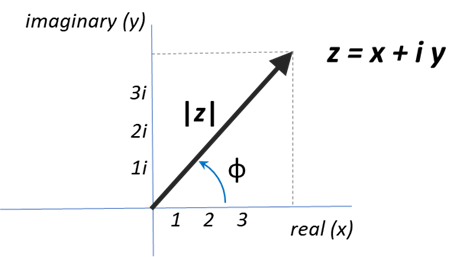

*The arrow from the origin represents a complex number; the dashed projections give its real and imaginary components, and the arc marks its phase.*


In [3]:
z = 3 - 2j
print("real part:", np.real(z))
print("imaginary part:", np.imag(z))

real part: 3.0
imaginary part: -2.0


The complex conjugate reverses the sign of the imaginary part:

$$
z^*=x-iy.
$$

Geometrically, conjugation reflects a point in the complex plane across the real axis; it is not a rotation by $\pi$.


In [4]:
print(z)
print(np.conj(z))
print(z.conjugate())

(3-2j)
(3+2j)
(3+2j)


The squared magnitude of $z=x+iy$ is obtained from its complex conjugate:

$$
|z|^2=zz^*=(x+iy)(x-iy)=x^2+y^2.
$$


In [5]:
print(z * z.conjugate())

(13+0j)


Therefore the **magnitude**, or absolute value, is

$$
|z|=\sqrt{zz^*}=\sqrt{x^2+y^2}.
$$


In [6]:
print(np.abs(z))
print(np.sqrt(z * z.conjugate()))

3.6055512754639896
(3.605551275463989+0j)


The real and imaginary parts can be recovered from $z$ and $z^*$:

$$
\operatorname{Re}z=\frac{z+z^*}{2},\qquad
\operatorname{Im}z=\frac{z-z^*}{2i}.
$$


In [7]:
z = 3 + 3j
print(np.real(z))
print((z + z.conjugate()) / 2)

3.0
(3+0j)


A nonzero complex number has polar form

$$
z=|z|(\cos\phi+i\sin\phi),
\qquad |z|=\sqrt{x^2+y^2}.
$$

The phase $\phi=\arg z$ must be placed in the correct quadrant. Numerically, use $\phi=\operatorname{atan2}(y,x)$, implemented by `np.angle`, rather than $\arctan(y/x)$, which is ambiguous and fails when $x=0$. The argument of $z=0$ is undefined.


In [8]:
# argument (angle) in rad

z = 3 + 3j

np.angle(z)

np.float64(0.7853981633974483)

### Euler's formula

$$
e^{i\phi}=\cos\phi+i\sin\phi,
\qquad (e^{i\phi})^*=e^{-i\phi}.
$$

Special cases include $e^{i0}=1$, $e^{i\pi/2}=i$, and $e^{i\pi}=-1$. Therefore

$$
\cos\phi=\frac{e^{i\phi}+e^{-i\phi}}{2},\qquad
\sin\phi=\frac{e^{i\phi}-e^{-i\phi}}{2i}.
$$


### Complex exponentials as phasors

For real $A$, a sinusoidal signal can be written

$$
A\cos(\omega t+\phi)=\operatorname{Re}\!\left[Ae^{i(\omega t+\phi)}\right].
$$

The real sinusoid is not equal to the complex exponential; taking the real part is part of the phasor convention. Quantum amplitudes are genuinely complex and should not generally be replaced by their real parts.


## Global phase, relative phase, and interference

Multiplying an entire state by $e^{i\gamma}$, with $\gamma\in\mathbb R$, leaves every inner-product magnitude and measurement probability unchanged:

$$
|\psi\rangle\sim e^{i\gamma}|\psi\rangle.
$$

Relative phase is observable through interference. The states

$$
|+\rangle=\frac{|0\rangle+|1\rangle}{\sqrt2},\qquad
|-\rangle=\frac{|0\rangle-|1\rangle}{\sqrt2}
$$

have identical computational-basis probabilities, but a Hadamard maps them to different deterministic outcomes: $H|+\rangle=|0\rangle$ and $H|-\rangle=|1\rangle$.


In [9]:
plus = np.array([1, 1], dtype=complex) / np.sqrt(2)
minus = np.array([1, -1], dtype=complex) / np.sqrt(2)
hadamard = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

print("before H:", np.abs(plus) ** 2, np.abs(minus) ** 2)
print("after H:", np.abs(hadamard @ plus) ** 2, np.abs(hadamard @ minus) ** 2)

before H: [0.5 0.5] [0.5 0.5]
after H: [1. 0.] [0. 1.]


### Complex vectors and matrices

An abstract complex vector has complex scalar coefficients. After a basis is chosen, ket coordinates are conventionally stored as a column:

$$
\mathbf v=\begin{bmatrix}3+2i\\-1+4i\\5-3i\end{bmatrix}.
$$

The corresponding row of conjugated coordinates represents the dual vector $\mathbf v^\dagger$, not a second orientation of the same coordinate array. A complex matrix has complex entries; for example,

$$
A=\begin{bmatrix}1+2i&3-i\\-2+i&4+5i\end{bmatrix}.
$$


**Complex conjugation** changes the sign of the imaginary part of every component. For a vector or matrix it is applied element by element and is denoted by an overbar or superscript `*`.


**Hermitian conjugation**, or taking the adjoint, combines complex conjugation and transposition:

$$
A^\dagger=(A^*)^T.
$$

For a column vector, the adjoint is a row vector. The adjoint reverses products: $(AB)^\dagger=B^\dagger A^\dagger$.


Complex conjugation of a complex vector:

$$\mathbf{v}^{*} = \begin{bmatrix} 3- 2i \\ -1 - 4 i \\ 5+3 i\end{bmatrix}$$

Hermitian conjugation of a complex vector:

$$\mathbf{v}^{\dagger} = \begin{bmatrix} 3- 2i & -1 - 4 i & 5+3 i\end{bmatrix}$$

Complex conjugation of a complex matrix:

$$\hat{A}^{*} = \begin{bmatrix} 1-2i & 3 + i \\ -2 - i & 4 - 5i\end{bmatrix}$$

Hermitian conjugation of a complex matrix:

$$\hat{A}^{\dagger} = \begin{bmatrix} 1-2i & -2 - i \\ 3 + i & 4 - 5i\end{bmatrix}$$


## Hermitian matrices

A square complex matrix is **Hermitian** when it is unchanged by taking the adjoint:

$$
\boxed{H^\dagger=(H^*)^T=H}.
$$


**Problem:** Prove that the matrix $C = \begin{bmatrix} 1 & i\\-i & 1 \end{bmatrix}$ is Hermitian.


In [10]:
C = np.array([[1, 1j], [-1j, 1]], dtype=complex)
print(C.conj().T - C)

[[ 0.-0.j -0.+0.j]
 [ 0.+0.j  0.-0.j]]


In [11]:
print("Hermitian:", np.allclose(C, C.conj().T))

Hermitian: True


## Linear transformations


A matrix defines a linear transformation after bases are selected. Depending on the matrix and vector, the transformation can change magnitude, direction, or complex phase. The matrix $2I$, for example, doubles every vector without changing its direction.


In [12]:
v = np.array([1,0])

A = np.array([[2,0],
              [0,2]])

v_trans = A@v

print(v_trans)

[2 0]


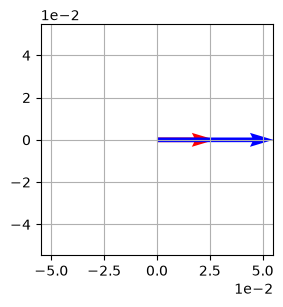

In [13]:
origin = np.zeros((2,2))  # Single origin

plt.figure(figsize=(3, 3))

plt.axis('equal')
plt.grid()
plt.ticklabel_format(style='sci', axis='both', scilimits=(0,0))

# Draw the vectors with adjusted scale
plt.quiver(origin[:, 0], origin[:, 1], [v[0], v_trans[0]], [v[1], v_trans[1]], 
           scale=4, color=['r', 'b'], width=0.02)

# Show the plot
plt.show()

*The red input vector and blue output vector remain on the horizontal axis, providing a baseline example of a transformation that preserves this direction.*


Now apply a different matrix:

$$
\begin{bmatrix}0&-1\\1&0\end{bmatrix}
\begin{bmatrix}1\\0\end{bmatrix}
=
\begin{bmatrix}0\\1\end{bmatrix}.
$$

This real orthogonal matrix rotates the vector by $90^\circ$ counterclockwise, so the direction changes while the magnitude is preserved.


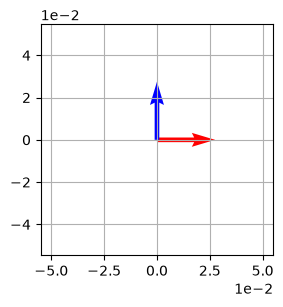

In [14]:
v = np.array([1,0])

A = np.array([[0,-1],
              [1,0]])

v_trans = A@v

origin = np.zeros((2,2))

plt.figure(figsize=(3, 3))

plt.axis('equal')
plt.grid()
plt.ticklabel_format(style='sci', axis='both', scilimits=(0,0))

plt.quiver(origin[:, 0], origin[:, 1], [v[0], v_trans[0]], [v[1], v_trans[1]], 
           scale=4, color=['r', 'b'], width=0.02)

plt.show()

*The red unit vector along $+x$ is rotated to the blue unit vector along $+y$, visualizing a $90^\circ$ counterclockwise rotation.*


In general, a linear transformation can change both magnitude and direction:

$$
\begin{bmatrix}2&1\\1&2\end{bmatrix}
\begin{bmatrix}1\\0\end{bmatrix}
=
\begin{bmatrix}2\\1\end{bmatrix}.
$$


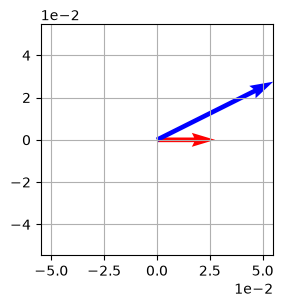

In [15]:
v = np.array([1,0])

A = np.array([[2,1],
              [1, 2]])

v_trans = A@v

origin = np.zeros((2,2))

plt.figure(figsize=(3, 3))

plt.axis('equal')
plt.grid()
plt.ticklabel_format(style='sci', axis='both', scilimits=(0,0))

plt.quiver(origin[:, 0], origin[:, 1], [v[0], v_trans[0]], [v[1], v_trans[1]], 
           scale=4, color=['r', 'b'], width=0.02)

plt.show()

*The red vector along $+x$ is mapped to the blue vector with both horizontal and vertical components, showing a linear transformation that changes direction and length.*


## Eigenvectors and eigenvalues

A nonzero vector $v$ is an eigenvector of a square matrix $A$ when

$$
Av=\lambda v.
$$

The scalar $\lambda$ is the corresponding eigenvalue. The transformation keeps the vector inside its one-dimensional complex span: it scales the magnitude by $|\lambda|$ and changes the phase by $\arg\lambda$ when $\lambda\neq0$. For a real eigenvector and real negative eigenvalue, this includes a reversal of direction.

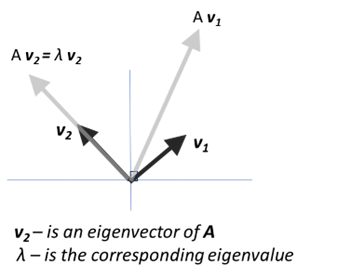

*Several vectors change direction under the transformation, whereas an eigenvector remains on its original line and is only scaled or phase shifted.*


In Python, <code>np.linalg.eig</code> returns an array of eigenvalues and a matrix whose columns are the corresponding eigenvectors.


In [16]:
A = np.array([[2, 1], [3, 5]], dtype=float)
eigenvalues, eigenvectors = np.linalg.eig(A)
display(eigenvalues, eigenvectors)

array([1.20871215+0.j, 5.79128785+0.j])

array([[-0.78419037+0.j, -0.25504011+0.j],
       [ 0.62052031+0.j, -0.96693047+0.j]])

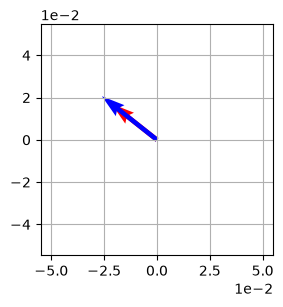

In [17]:
# Check the first eigenvector and its image.
v = eigenvectors[:, 0]
v_trans = A @ v

origin = np.zeros((2, 2))
plt.figure(figsize=(3, 3))
plt.axis("equal")
plt.grid()
plt.ticklabel_format(style="sci", axis="both", scilimits=(0, 0))
plt.quiver(
    origin[:, 0],
    origin[:, 1],
    [v[0], v_trans[0]],
    [v[1], v_trans[1]],
    scale=4,
    color=["r", "b"],
    width=0.02,
)
plt.show()

*The selected eigenvector and its transformed image are collinear; the eigenvalue changes its scale and possibly its orientation but not its one-dimensional span.*


Let us verify the eigenvalue equation $A\mathbf v=\lambda\mathbf v$ numerically.


In [18]:
left = A @ eigenvectors[:, 1]
right = eigenvalues[1] * eigenvectors[:, 1]
display(left, right)
print("eigenvalue equation:", np.allclose(left, right))

array([-1.4770107+0.j, -5.5997727+0.j])

array([-1.4770107+0.j, -5.5997727+0.j])

eigenvalue equation: True


## The finite-dimensional spectral theorem

If $H=H^\dagger$, then all eigenvalues of $H$ are real and there is an orthonormal basis of eigenvectors. Eigenvectors associated with distinct eigenvalues are orthogonal; degeneracy allows many possible orthonormal bases within the degenerate eigenspace.


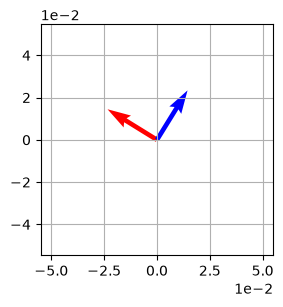

In [19]:
# For a Hermitian matrix, use eigh to obtain an orthonormal eigenbasis.
A = np.array([[2, 1], [1, 3]], dtype=float)
eVals, eVecs = np.linalg.eigh(A)

v1 = eVecs[:, 0]
v2 = eVecs[:, 1]
origin = np.zeros((2, 2))

plt.figure(figsize=(3, 3))
plt.axis("equal")
plt.grid()
plt.ticklabel_format(style="sci", axis="both", scilimits=(0, 0))
plt.quiver(
    origin[:, 0],
    origin[:, 1],
    [v1[0], v2[0]],
    [v1[1], v2[1]],
    scale=4,
    color=["r", "b"],
    width=0.02,
)
plt.show()

*The two orthonormal eigenvectors of the Hermitian matrix are shown with their transformed images, each aligned with its original eigendirection and scaled by a real eigenvalue.*


In [20]:
# Hermitian eigenvalues returned by eigh are real.
eVals

array([1.38196601, 3.61803399])

In [21]:
H_complex = np.array([[2, 1j], [-1j, 3]], dtype=complex)
eigenvalues, eigenvectors = np.linalg.eigh(H_complex)
v1, v2 = eigenvectors[:, 0], eigenvectors[:, 1]

print("inner product:", np.vdot(v1, v2))
print("real eigenvalues:", eigenvalues)
print("reconstruction:", np.allclose(eigenvectors @ np.diag(eigenvalues) @ eigenvectors.conj().T, H_complex))

inner product: 0j
real eigenvalues: [1.38196601 3.61803399]
reconstruction: True


In finite-dimensional quantum mechanics, observables are represented by Hermitian operators. Their real eigenvalues are possible outcomes of an ideal projective measurement, while their spectral projectors describe the corresponding outcome subspaces.


**Example: the hydrogen atom.** In the nonrelativistic fixed-proton approximation, its Hamiltonian is

$$
\hat H=\frac{\hat{\mathbf p}^{\,2}}{2m_e}
-\frac{e^2}{4\pi\varepsilon_0\,\hat r}.
$$

The Hamiltonian is self-adjoint on an appropriate domain. Its negative-energy bound states form a discrete spectrum, while ionized scattering states belong to a continuous spectrum. This is why the finite-matrix spectral theorem must be extended with care for infinite-dimensional quantum systems.

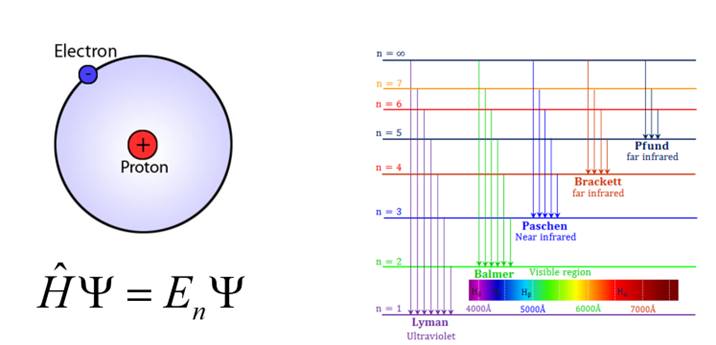

*The left panel gives a simple electron–proton picture; the right panel organizes hydrogen emission transitions into the Lyman, Balmer, Paschen, Brackett, and Pfund series.*


## Spectral projectors and functions of an operator

If a finite-dimensional Hermitian operator has spectral decomposition

$$
H=\sum_k \lambda_k P_k,
$$

then $P_k$ projects onto the eigenspace with eigenvalue $\lambda_k$, the projectors satisfy $P_jP_k=\delta_{jk}P_k$, and $\sum_kP_k=I$. Functions of $H$ act on its eigenvalues:

$$
f(H)=\sum_k f(\lambda_k)P_k.
$$

This identity underlies projective measurement and, for a time-independent Hamiltonian, time evolution $e^{-iHt/\hbar}$.


In [22]:
projectors = [np.outer(eigenvectors[:, k], eigenvectors[:, k].conj()) for k in range(2)]
spectral_sum = sum(eigenvalues[k] * projectors[k] for k in range(2))

print("projectors sum to identity:", np.allclose(sum(projectors), np.eye(2)))
print("spectral reconstruction:", np.allclose(spectral_sum, H_complex))

projectors sum to identity: True
spectral reconstruction: True


## Unitary operators


Unitary operators preserve inner products, norms, and orthogonality. They describe reversible evolution of a closed quantum system and ideal quantum gates. A unitary matrix can also represent a passive change between orthonormal coordinate bases; an active gate instead changes the state relative to a fixed basis. These two interpretations use the same algebra but describe different viewpoints.


For vectors $a$ and $b$,

$$
\langle Ua|Ub\rangle=(Ua)^\dagger(Ub)=a^\dagger U^\dagger U b.
$$

This equals $\langle a|b\rangle$ for every pair $a,b$ exactly when

$$
U^\dagger U=I.
$$

For a square matrix this is equivalent to $UU^\dagger=I$ and $U^{-1}=U^\dagger$.


**Properties of square unitary matrices:**

- A product of unitary matrices is unitary.
- The inverse of a unitary matrix is unitary and equals its adjoint.
- The rows form an orthonormal basis, as do the columns.


**Example 1.** Verify that

$$
U=\frac{1}{\sqrt2}\begin{bmatrix}1&1\\i&-i\end{bmatrix}
$$

is unitary.


In [23]:
U = np.array([[1, 1], [1j, -1j]], dtype=complex) / np.sqrt(2)

print(U.conj().T @ U)
print("unitary:", np.allclose(U.conj().T @ U, np.eye(2)))
print("adjoint equals inverse:", np.allclose(U.conj().T, np.linalg.inv(U)))

[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]
unitary: True
adjoint equals inverse: True


**Example 2.** Verify that the Hadamard matrix

$$
H=\frac{1}{\sqrt2}\begin{bmatrix}1&1\\1&-1\end{bmatrix}
$$

is unitary.


In [24]:
H_gate = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
print(H_gate.conj().T @ H_gate)

[[ 1.00000000e+00+0.j -2.23711432e-17+0.j]
 [-2.23711432e-17+0.j  1.00000000e+00+0.j]]


## Hermitian generators produce unitary transformations

If $G=G^\dagger$ and $\theta\in\mathbb R$, then

$$
U(\theta)=e^{-i\theta G}
$$

is unitary. For a Pauli matrix, the identity $\sigma_k^2=I$ gives

$$
e^{-i\theta\sigma_k/2}
=\cos\frac\theta2 I-i\sin\frac\theta2\sigma_k.
$$

This is the algebraic form of a qubit rotation by angle $\theta$ about axis $k$ on the Bloch sphere.


In [25]:
sigma_z = np.array([[1, 0], [0, -1]], dtype=complex)
theta = np.pi / 3
rotation_z = expm(-1j * theta * sigma_z / 2)
closed_form = np.cos(theta / 2) * np.eye(2) - 1j * np.sin(theta / 2) * sigma_z

print("matches closed form:", np.allclose(rotation_z, closed_form))
print("unitary:", np.allclose(rotation_z.conj().T @ rotation_z, np.eye(2)))

matches closed form: True
unitary: True


## Dirac notation


A ket $|A\rangle$ is a vector; its associated bra is the linear functional

$$
\langle A|=|A\rangle^\dagger.
$$

In an orthonormal coordinate basis,

$$
|A\rangle=\begin{bmatrix}a_1\\a_2\\\vdots\\a_n\end{bmatrix},
\qquad
\langle A|=\begin{bmatrix}a_1^*&a_2^*&\cdots&a_n^*\end{bmatrix}.
$$

For example,

$$
|A\rangle=\begin{bmatrix}2+i\\1-3i\end{bmatrix}
\quad\Longrightarrow\quad
\langle A|=\begin{bmatrix}2-i&1+3i\end{bmatrix}.
$$


The *inner product* is

$$
\langle A|B\rangle
=
\begin{bmatrix}a_1^*&a_2^*&\cdots&a_n^*\end{bmatrix}
\begin{bmatrix}b_1\\b_2\\\vdots\\b_n\end{bmatrix}
=\sum_{k=1}^n a_k^*b_k,
$$

which is a scalar. The *outer product* is

$$
|A\rangle\langle B|
=
\begin{bmatrix}a_1\\a_2\\\vdots\\a_n\end{bmatrix}
\begin{bmatrix}b_1^*&b_2^*&\cdots&b_n^*\end{bmatrix},
$$

an $n\times n$ matrix whose $(j,k)$ entry is $a_jb_k^*$.


## Active transformations and passive basis changes

An active unitary sends $|\psi\rangle\mapsto U|\psi\rangle$ while a basis is held fixed. For a passive basis change, let the columns of a unitary matrix $V$ be the new orthonormal basis vectors expressed in the old coordinates. State coordinates and operator matrices then transform as

$$
|\psi\rangle_{\mathrm{new}}=V^\dagger|\psi\rangle,
\qquad A_{\mathrm{new}}=V^\dagger A V.
$$

Physical expectation values are invariant:

$$
\langle\psi|A|\psi\rangle
=\langle\psi_{\mathrm{new}}|A_{\mathrm{new}}|\psi_{\mathrm{new}}\rangle.
$$


In [26]:
psi = np.array([1, 1j], dtype=complex) / np.sqrt(2)
A_observable = np.array([[1, 1], [1, -1]], dtype=complex)
V = hadamard

psi_new = V.conj().T @ psi
A_new = V.conj().T @ A_observable @ V

old_expectation = np.vdot(psi, A_observable @ psi)
new_expectation = np.vdot(psi_new, A_new @ psi_new)
print(old_expectation, new_expectation)
print("invariant:", np.allclose(old_expectation, new_expectation))

0j 0j
invariant: True


In [27]:
display(Bra(0) * Ket(1), Ket(1) * Bra(0))

<0|1>

|1><0|

In [28]:
qapply(Bra(0)*(Ket(0)+Ket(1))/sqrt(2))

sqrt(2)*<0|0>/2 + sqrt(2)*<0|1>/2

[SymPy Physics Quantum documentation](https://docs.sympy.org/latest/modules/physics/quantum/index.html)


## Key takeaways

- Complex conjugation is essential in adjoints, norms, overlaps, and probability amplitudes.
- The finite-dimensional spectral theorem decomposes a Hermitian operator into real eigenvalues and orthogonal projectors.
- Unitary evolution preserves norms and inner products; Hermitian generators produce one-parameter unitary families.
- Dirac notation is coordinate independent, while a matrix appears only after bases are chosen.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. M. A. Nielsen and I. L. Chuang, [*Quantum Computation and Quantum Information*](https://www.cambridge.org/highereducation/books/quantum-computation-and-quantum-information/01E10196D0A682A6AEFFEA52D53BE9AE), Section 2.1.
2. J. Preskill, [Quantum Computation lecture notes](https://www.preskill.caltech.edu/ph229/), Chapter 2.
3. [SymPy Physics Quantum documentation](https://docs.sympy.org/latest/modules/physics/quantum/index.html).
4. [SciPy matrix exponential](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.expm.html).
5. [Qiskit `Operator` API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Operator).
